# Simple — примеры объектов

## 1. Данные

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'data' / 'train.csv').exists())
train = pd.read_csv(ROOT / 'data' / 'train.csv')
train_dir = ROOT / 'data' / 'train'

print('Объектов с simple:', train['simple'].sum())

Объектов с simple: 1929


## 2. Пять примеров simple

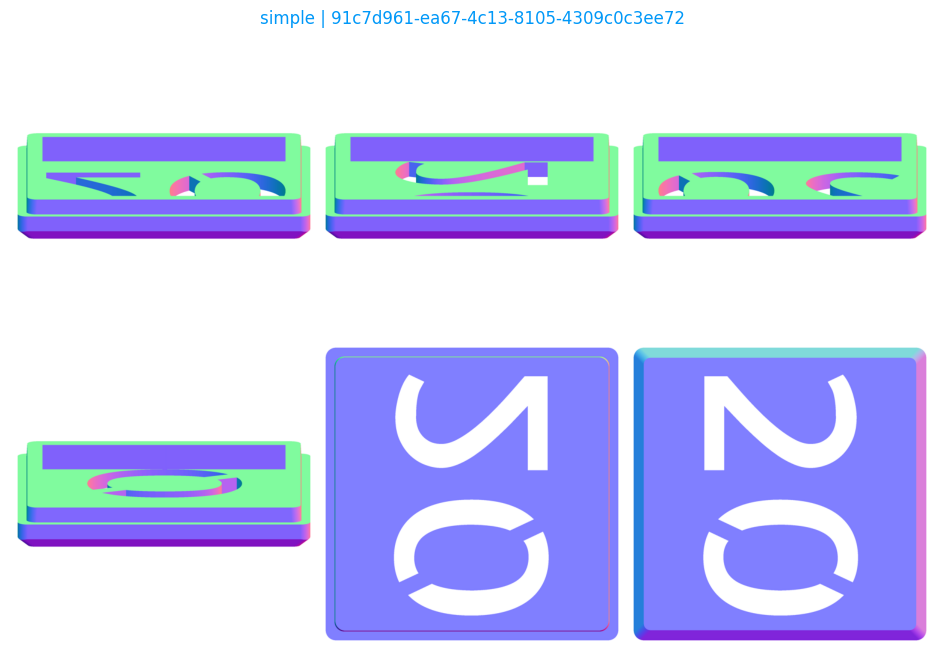

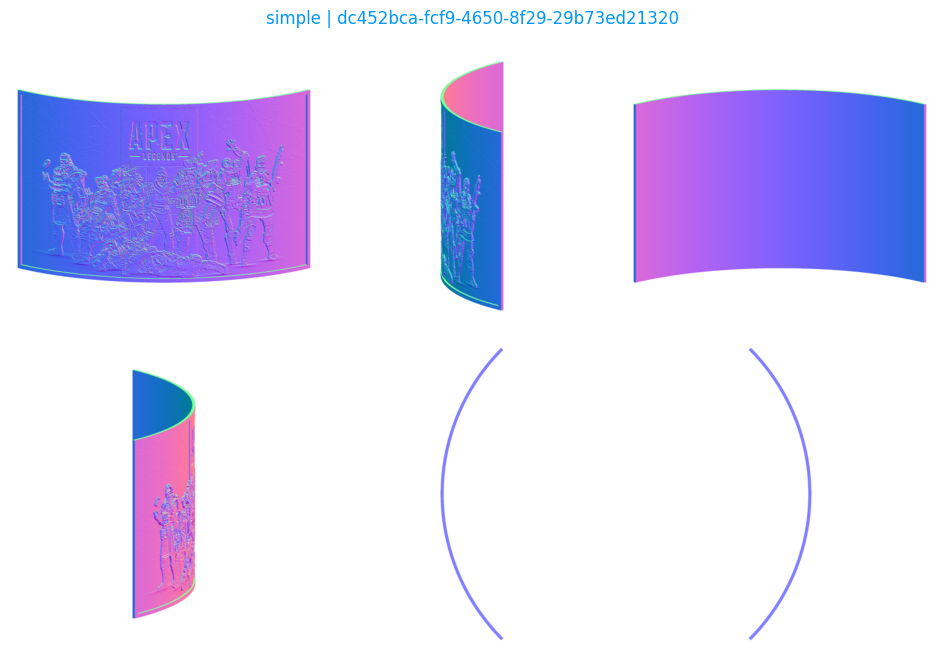

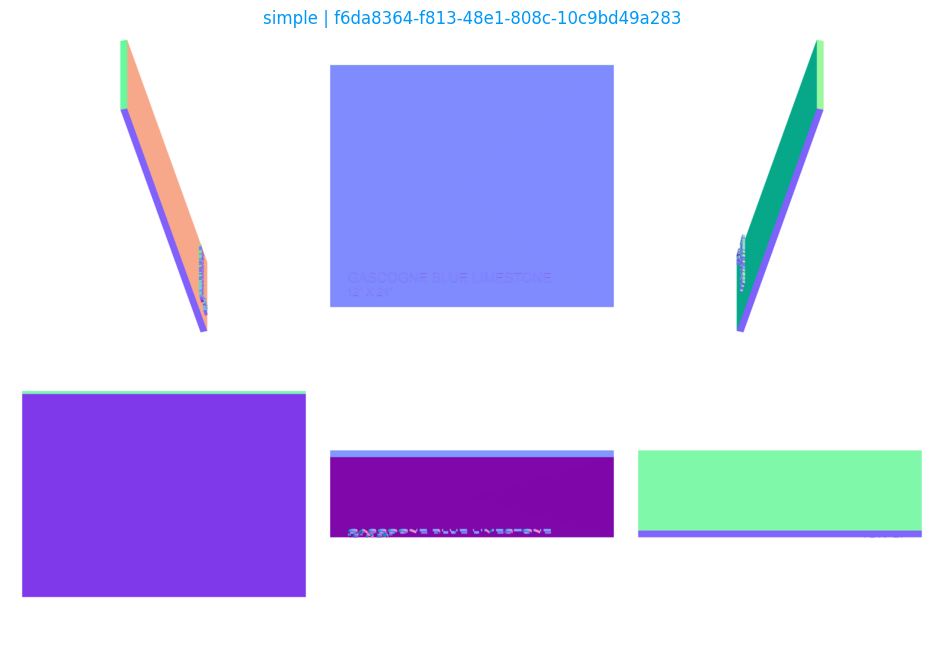

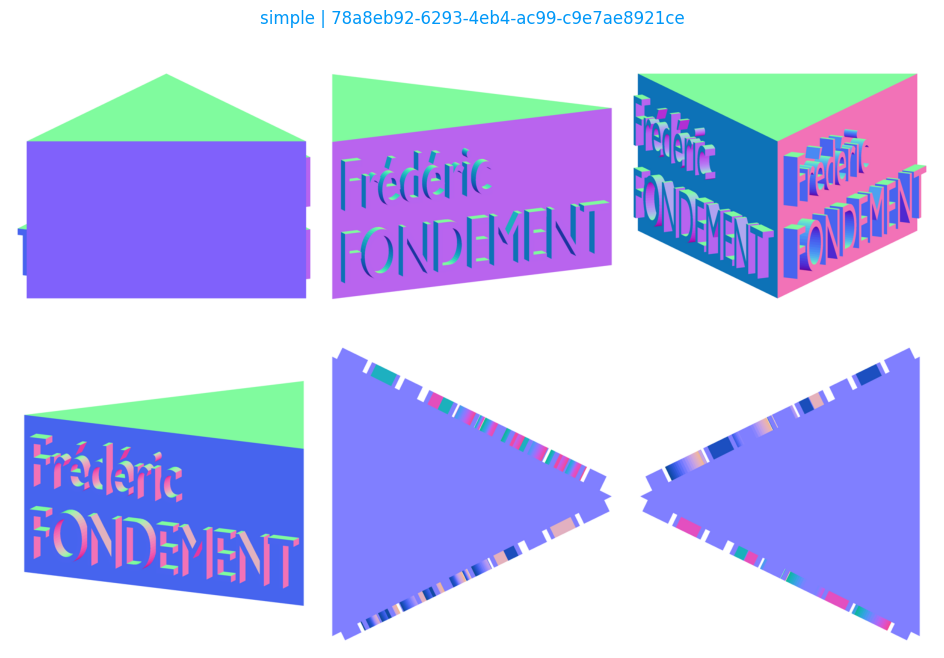

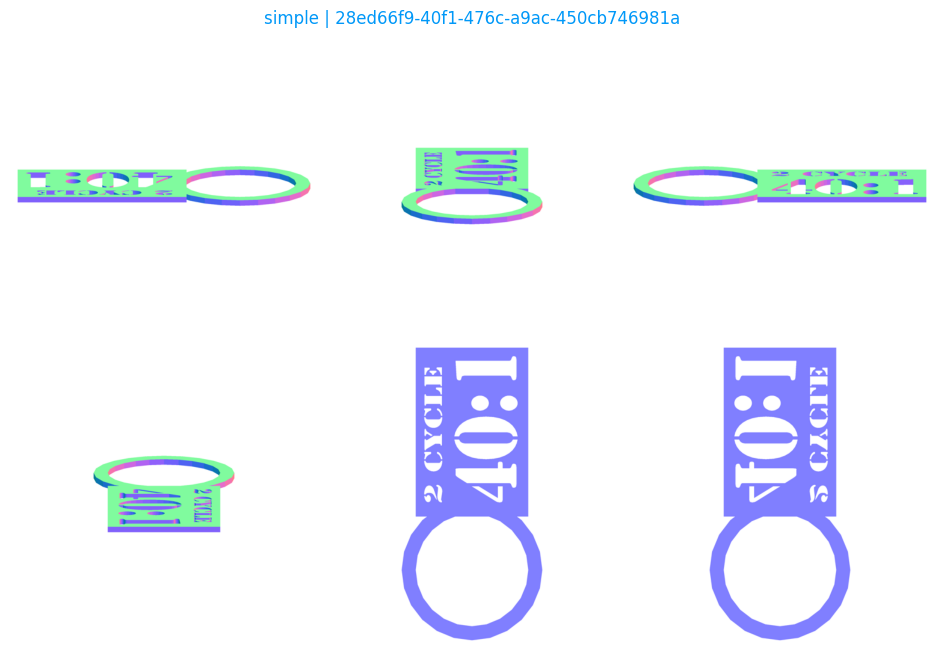

In [2]:
examples = train[train['simple'] == 1].sample(5, random_state=42)
defect_columns = train.columns.drop(['item_id', 'quality'])

for _, row in examples.iterrows():
    other_defects = [name for name in defect_columns
                     if name != 'simple' and row[name] == 1]
    title = f"simple | {row['item_id']}"
    if other_defects:
        title += f" | ещё: {', '.join(other_defects)}"

    with Image.open(train_dir / f"{row['item_id']}.png") as image:
        plt.figure(figsize=(12, 8))
        plt.imshow(image)
        plt.title(title, color='#0098F8')
        plt.axis('off')
        plt.show()

## 3. Validation

In [3]:
%pip install -q catboost iterative-stratification

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

target_columns = train.columns.drop('item_id').tolist()

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)
train_val_index, _ = next(splitter.split(train, train[target_columns]))
train_val_df = train.iloc[train_val_index].reset_index(drop=True)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=0.1765, random_state=43
)
_, val_index = next(splitter.split(train_val_df, train_val_df[target_columns]))
val_df = train_val_df.iloc[val_index].reset_index(drop=True).copy()

print('Validation:', len(val_df))
print('Объектов с simple:', val_df['simple'].sum())

Validation: 1361
Объектов с simple: 289


## 4. Готовый CatBoost

In [5]:
import json
from catboost import CatBoostClassifier

archive_dir = ROOT / 'archive'
with open(archive_dir / 'artifacts' / 'catboost_features_config.json', encoding='utf-8') as file:
    config = json.load(file)

assert config['target_columns'] == target_columns
feature_columns = config['feature_columns']
features = pd.read_csv(
    archive_dir / 'artifacts' / 'train_mesh_features_relative.csv'
).set_index('item_id')
X_val = features.loc[val_df['item_id'], feature_columns]
assert X_val.index.tolist() == val_df['item_id'].tolist()
assert np.isfinite(X_val.to_numpy()).all()

model = CatBoostClassifier()
model.load_model(str(archive_dir / 'models' / 'catboost_features' / 'simple.cbm'))
assert model.feature_names_ == feature_columns

threshold = config['thresholds'][target_columns.index('simple')]
val_df['probability'] = model.predict_proba(X_val)[:, 1]
val_df['prediction'] = (val_df['probability'] >= threshold).astype(int)
print('Threshold:', round(threshold, 2))

Threshold: 0.25


## 5. Результат и количество ошибок

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = val_df['simple']
y_pred = val_df['prediction']
print('Precision:', round(precision_score(y_true, y_pred), 4))
print('Recall:', round(recall_score(y_true, y_pred), 4))
print('F1:', round(f1_score(y_true, y_pred), 4))

false_positive = val_df[(y_true == 0) & (y_pred == 1)]
false_negative = val_df[(y_true == 1) & (y_pred == 0)]
print('Ложных срабатываний:', len(false_positive))
print('Пропущенных simple:', len(false_negative))

Precision: 0.5964
Recall: 0.7924
F1: 0.6805
Ложных срабатываний: 155
Пропущенных simple: 60


## 6. Примеры ошибок

Ложные срабатывания:


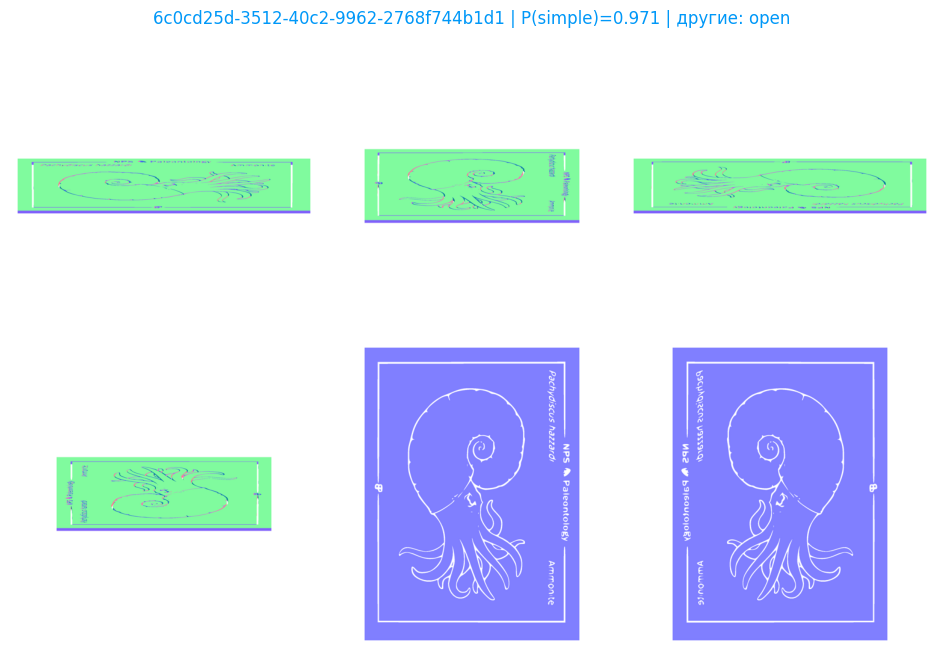

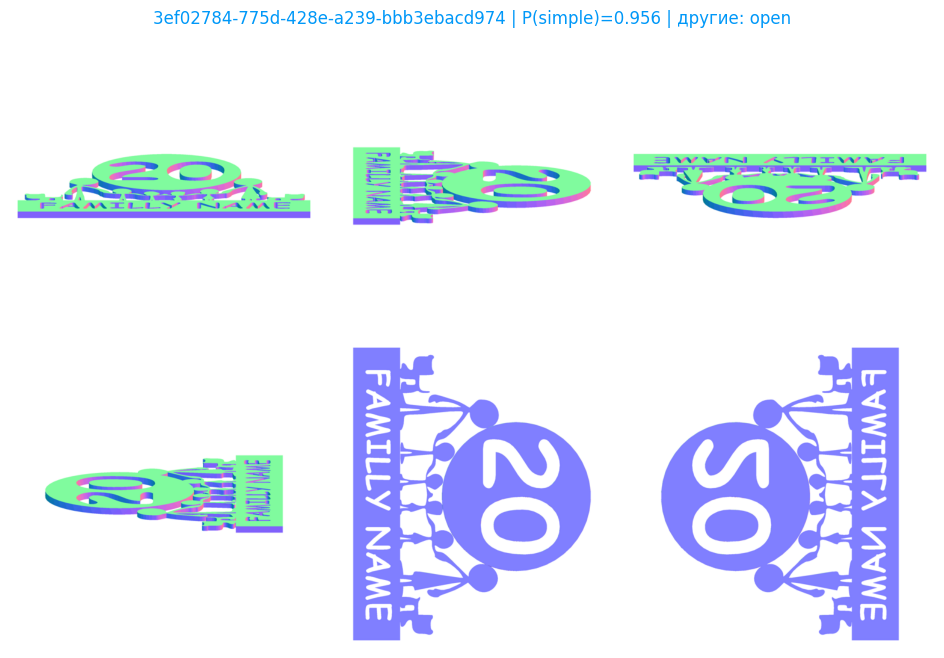

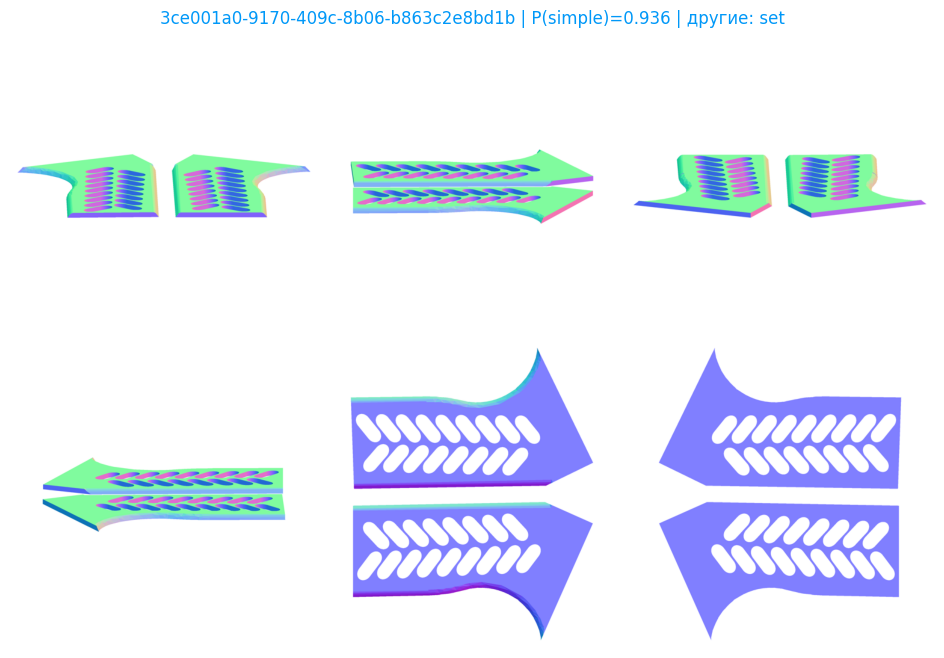

Пропущенные simple:


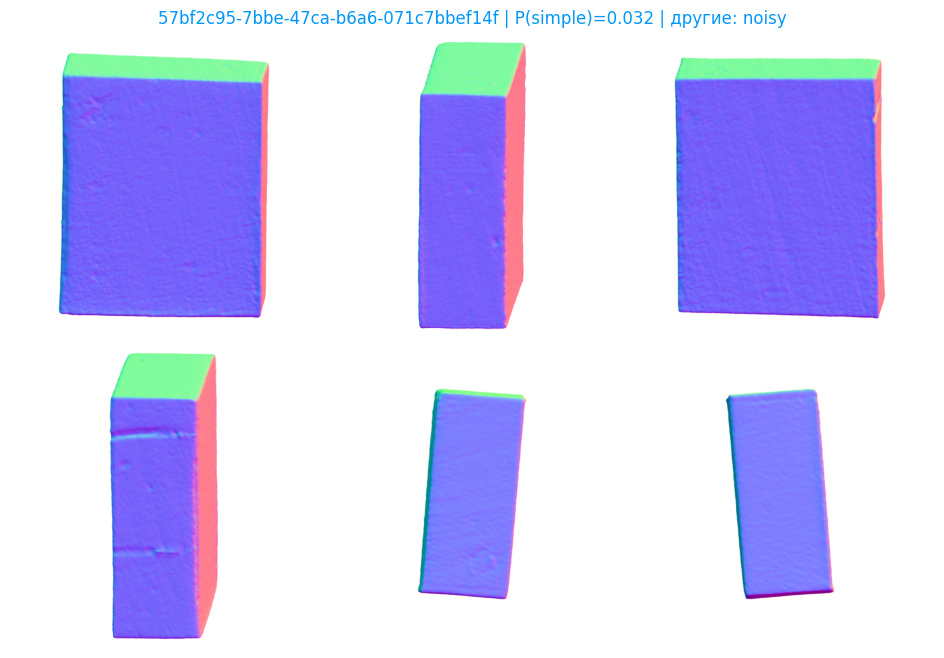

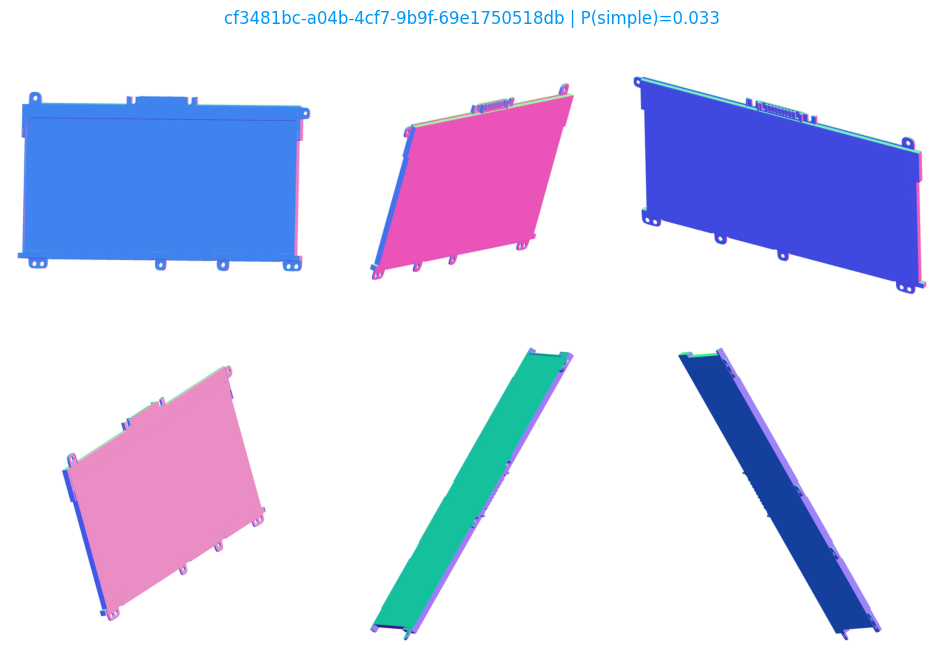

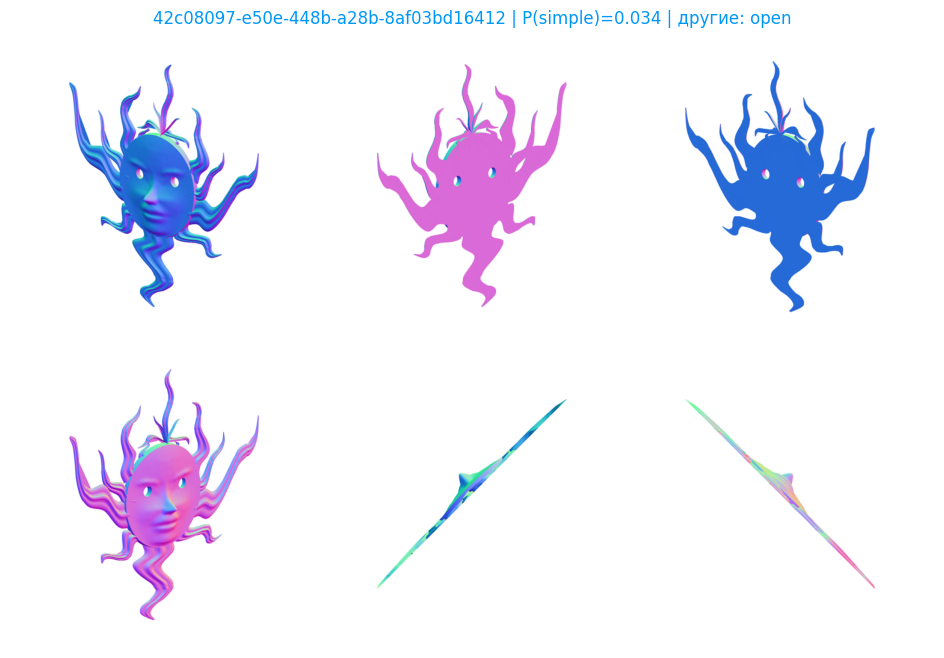

In [7]:
def show_mistakes(rows, title):
    print(title)
    for _, row in rows.iterrows():
        other_defects = [name for name in defect_columns
                         if name != 'simple' and row[name] == 1]
        label = f"{row['item_id']} | P(simple)={row['probability']:.3f}"
        if other_defects:
            label += f" | другие: {', '.join(other_defects)}"

        with Image.open(train_dir / f"{row['item_id']}.png") as image:
            plt.figure(figsize=(12, 8))
            plt.imshow(image)
            plt.title(label, color='#0098F8')
            plt.axis('off')
            plt.show()

show_mistakes(
    false_positive.sort_values('probability', ascending=False).head(3),
    'Ложные срабатывания:'
)
show_mistakes(
    false_negative.sort_values('probability').head(3),
    'Пропущенные simple:'
)

## 7. Готовая ResNet18

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18
from tqdm.auto import tqdm

image_transform = transforms.Compose([
    transforms.Resize((224, 336)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class RenderDataset(Dataset):
    def __init__(self, item_ids):
        self.item_ids = item_ids.tolist()

    def __len__(self):
        return len(self.item_ids)

    def __getitem__(self, index):
        with Image.open(train_dir / f'{self.item_ids[index]}.png') as image:
            return image_transform(image.convert('RGB'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint = torch.load(
    archive_dir / 'models' / 'resnet' / 'best_resnet18_improved.pth',
    map_location=device,
    weights_only=True
)
assert checkpoint['target_columns'] == target_columns

resnet_model = resnet18(weights=None)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, len(target_columns))
resnet_model.load_state_dict(checkpoint['model_state_dict'])
resnet_model = resnet_model.to(device).eval()

val_loader = DataLoader(RenderDataset(val_df['item_id']), batch_size=32, shuffle=False, num_workers=0)
print('Устройство:', device)
print('Batch:', len(val_loader))

Устройство: cpu
Batch: 43


c:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
resnet_probabilities = []
simple_index = target_columns.index('simple')

with torch.inference_mode():
    for images in tqdm(val_loader, desc='ResNet18 validation'):
        logits = resnet_model(images.to(device))
        resnet_probabilities.append(torch.sigmoid(logits)[:, simple_index].cpu().numpy())

val_df['resnet_probability'] = np.concatenate(resnet_probabilities)
with open(archive_dir / 'artifacts' / 'resnet' / 'resnet18_improved_thresholds.json', encoding='utf-8') as file:
    resnet_threshold = json.load(file)['simple']
val_df['resnet_prediction'] = (val_df['resnet_probability'] >= resnet_threshold).astype(int)

print('Threshold ResNet18:', round(resnet_threshold, 2))

ResNet18 validation: 100%|██████████| 43/43 [02:04<00:00,  2.88s/it]

Threshold ResNet18: 0.45


## 8. Сравнение моделей

In [10]:
with open(archive_dir / 'artifacts' / 'resnet_catboost_features_config.json', encoding='utf-8') as file:
    fusion_config = json.load(file)
assert fusion_config['target_columns'] == target_columns

val_df['fusion_probability'] = (
    fusion_config['resnet_weight'] * val_df['resnet_probability']
    + fusion_config['catboost_weight'] * val_df['probability']
)
fusion_threshold = fusion_config['thresholds']['simple']
val_df['fusion_prediction'] = (val_df['fusion_probability'] >= fusion_threshold).astype(int)

rows = []
for name, column in [('CatBoost', 'prediction'), ('ResNet18', 'resnet_prediction'),
                     ('Связка', 'fusion_prediction')]:
    predicted = val_df[column]
    rows.append({
        'Модель': name,
        'Precision': precision_score(y_true, predicted),
        'Recall': recall_score(y_true, predicted),
        'F1': f1_score(y_true, predicted),
        'FP': int(((y_true == 0) & (predicted == 1)).sum()),
        'FN': int(((y_true == 1) & (predicted == 0)).sum())
    })

pd.DataFrame(rows).round(4)

,Модель,Precision,Recall,F1,FP,FN
0,CatBoost,0.5964,0.7924,0.6805,155,60
1,ResNet18,0.5863,0.8581,0.6966,175,41
2,Связка,0.6415,0.7924,0.7090,128,60


## 9. Только simple и несколько дефектов

In [11]:
other_columns = [name for name in defect_columns if name != 'simple']
only_simple = val_df[other_columns].sum(axis=1) == 0
group_rows = []

for group_name, mask in [('Только simple', only_simple), ('Simple + другие', ~only_simple)]:
    group = val_df[mask & val_df['simple'].eq(1)]
    for model_name, column in [('CatBoost', 'prediction'),
                               ('ResNet18', 'resnet_prediction'),
                               ('Связка', 'fusion_prediction')]:
        group_rows.append({
            'Группа': group_name,
            'Модель': model_name,
            'Объектов': len(group),
            'Пропущено': int(group[column].eq(0).sum()),
            'Recall': group[column].mean()
        })

pd.DataFrame(group_rows).round(3)

,Группа,Модель,Объектов,Пропущено,Recall
0,Только simple,CatBoost,210,30,0.857
1,Только simple,ResNet18,210,17,0.919
2,Только simple,Связка,210,26,0.876
3,Simple + другие,CatBoost,79,30,0.620
4,Simple + другие,ResNet18,79,24,0.696
5,Simple + другие,Связка,79,34,0.570


## 10. Где модели помогают друг другу

CatBoost пропустил, ResNet18 нашла: 39
ResNet18 пропустила, CatBoost нашёл: 20
Нашла ResNet18:


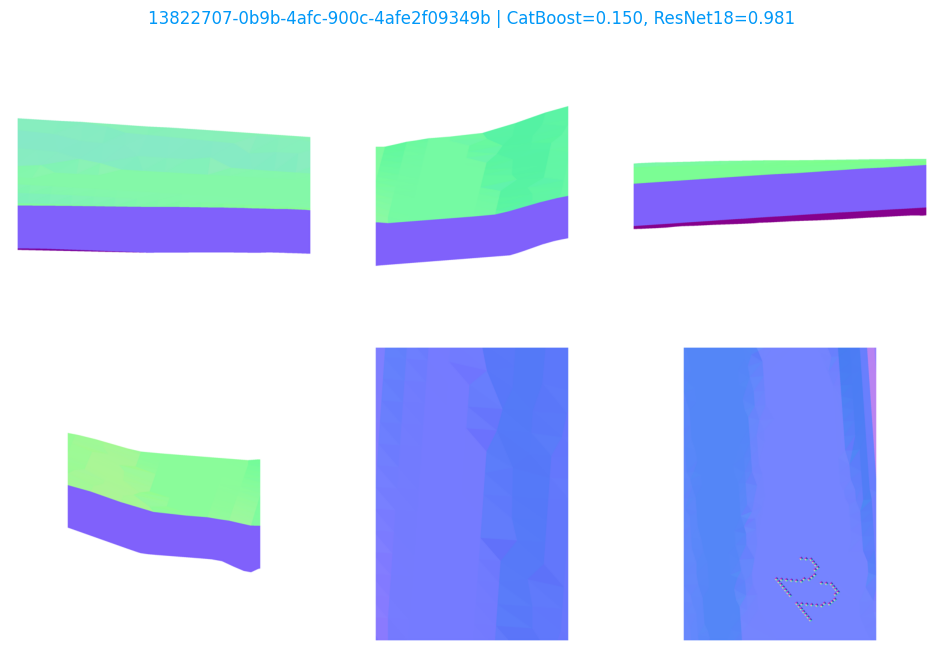

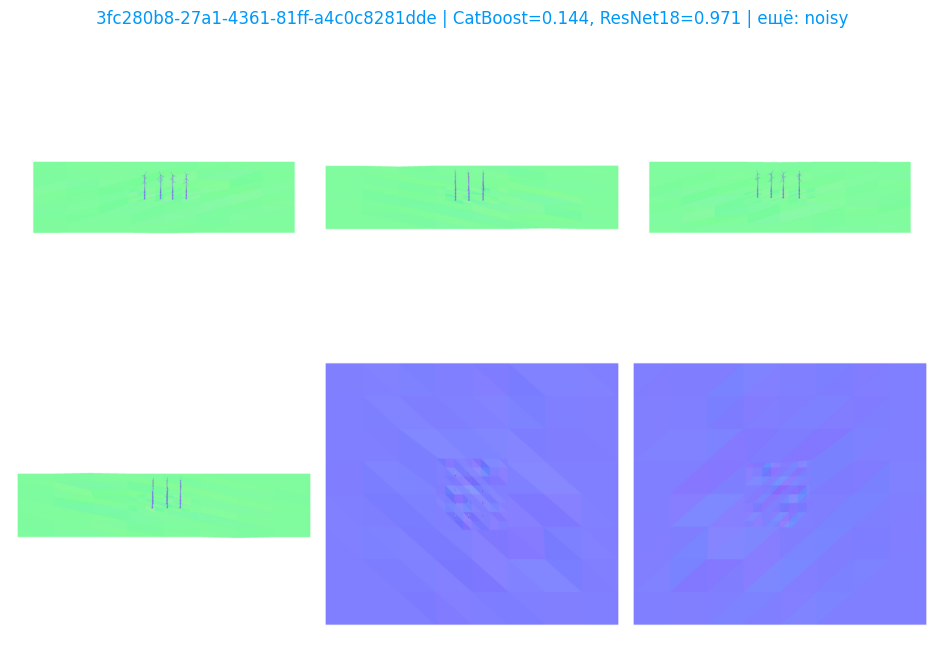

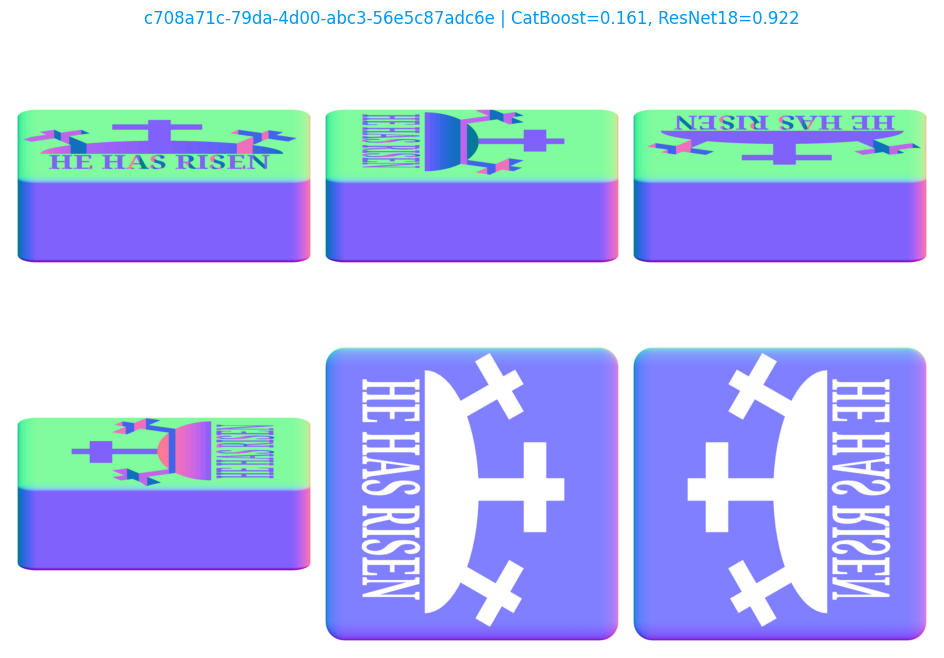

Нашёл CatBoost:


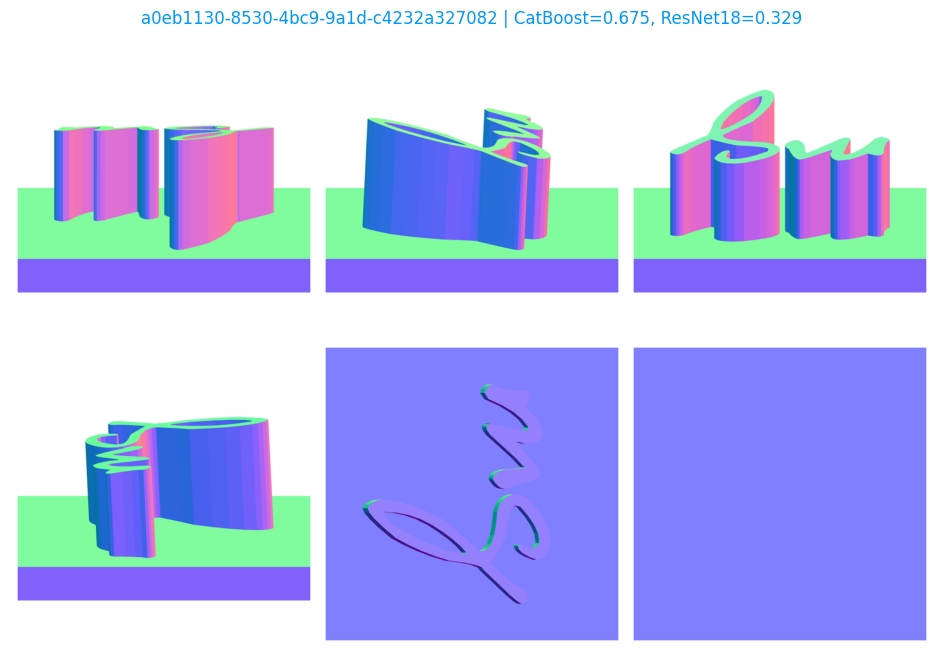

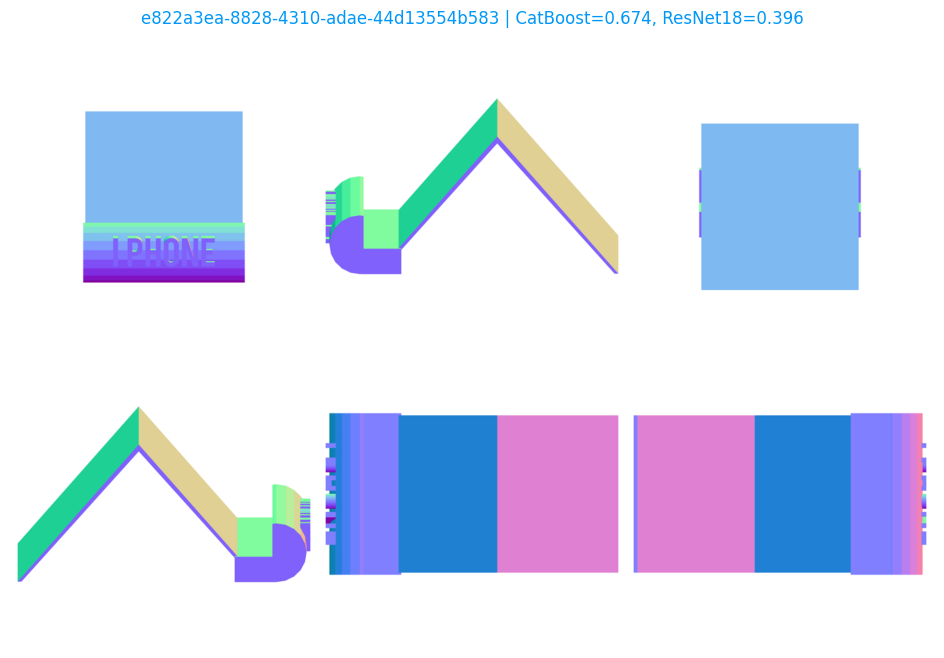

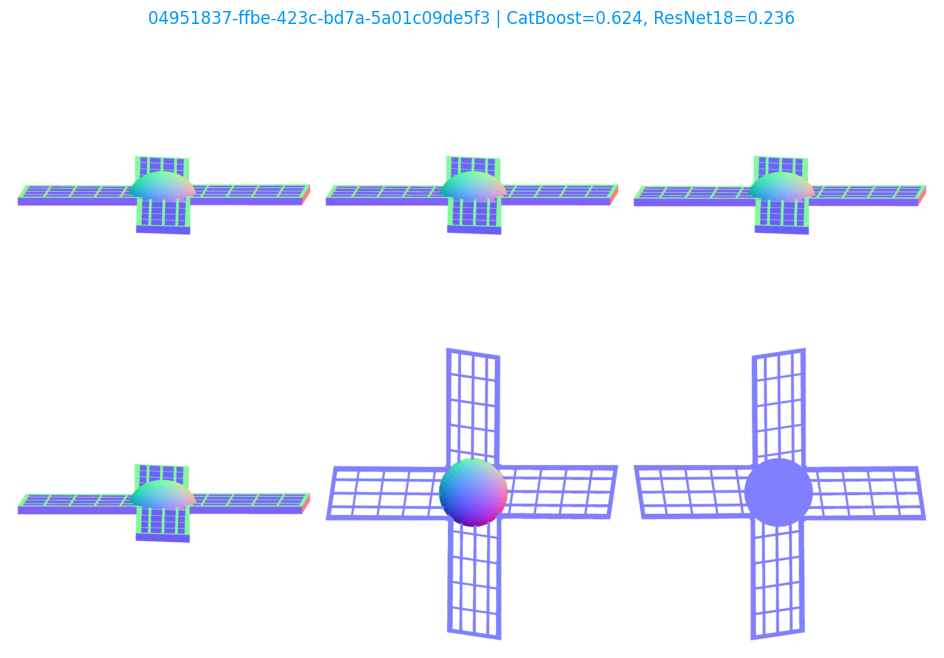

In [12]:
catboost_missed = val_df[
    val_df['simple'].eq(1)
    & val_df['prediction'].eq(0)
    & val_df['resnet_prediction'].eq(1)
]
resnet_missed = val_df[
    val_df['simple'].eq(1)
    & val_df['prediction'].eq(1)
    & val_df['resnet_prediction'].eq(0)
]

print('CatBoost пропустил, ResNet18 нашла:', len(catboost_missed))
print('ResNet18 пропустила, CatBoost нашёл:', len(resnet_missed))

def show_comparison(rows, title):
    print(title)
    for _, row in rows.head(3).iterrows():
        other = [name for name in other_columns if row[name] == 1]
        label = (f"{row['item_id']} | CatBoost={row['probability']:.3f}, "
                 f"ResNet18={row['resnet_probability']:.3f}")
        if other:
            label += f" | ещё: {', '.join(other)}"

        with Image.open(train_dir / f"{row['item_id']}.png") as image:
            plt.figure(figsize=(12, 8))
            plt.imshow(image)
            plt.title(label, color='#0098F8')
            plt.axis('off')
            plt.show()

show_comparison(catboost_missed.sort_values('resnet_probability', ascending=False),
                'Нашла ResNet18:')
show_comparison(resnet_missed.sort_values('probability', ascending=False),
                'Нашёл CatBoost:')

## 11. Другие дефекты у пропущенных simple

In [ ]:
missed_simple = val_df[val_df['simple'].eq(1) & val_df['prediction'].eq(0)]
print('Только simple:', int(missed_simple[other_columns].sum(axis=1).eq(0).sum()))
print('Simple + другие:', int(missed_simple[other_columns].sum(axis=1).gt(0).sum()))

pd.DataFrame({
    'Другой дефект': other_columns,
    'Среди пропущенных': missed_simple[other_columns].sum().values
}).sort_values('Среди пропущенных', ascending=False).reset_index(drop=True)

## 12. Геометрия пропусков: выборка

In [13]:
# Все пропуски и две случайные группы для сравнения.
fn_rows = val_df[val_df['simple'].eq(1) & val_df['prediction'].eq(0)]
tp_rows = val_df[val_df['simple'].eq(1) & val_df['prediction'].eq(1)]
negative_rows = val_df[val_df['simple'].eq(0)]
groups = []
for name, rows in [('FN', fn_rows), ('TP', tp_rows), ('Not simple', negative_rows)]:
    selected = rows if name == 'FN' else rows.sample(min(len(fn_rows), len(rows)), random_state=42)
    groups.append(selected.assign(group=name))
geometry_rows = pd.concat(groups, ignore_index=True)
geometry_rows.groupby('group').size().rename('Объектов')

group
FN            60
Not simple    60
TP            60
Name: Объектов, dtype: int64

## 13. Толщина, форма и нормали

In [14]:
from tqdm.auto import tqdm

def geometry_features(item_id):
    rng = np.random.default_rng(42)
    with np.load(train_dir / f'{item_id}.npz') as mesh:
        vertices = mesh['vertices']
        faces = mesh['faces']
        vertex_ids = rng.choice(len(vertices), min(len(vertices), 20000), replace=False)
        points = vertices[vertex_ids].astype(np.float64)
        face_ids = rng.choice(len(faces), min(len(faces), 5000), replace=False)
        triangles = vertices[faces[face_ids]].astype(np.float64)

    del vertices, faces
    centered = points - points.mean(axis=0)
    eigenvalues, axes = np.linalg.eigh(np.cov(centered, rowvar=False))
    eigenvalues = np.maximum(eigenvalues, 0)
    extent = np.ptp(centered @ axes, axis=0)
    result = {
        'pca_thickness': np.sqrt(eigenvalues[0] / max(eigenvalues[2], 1e-15)),
        'pca_line_ratio': np.sqrt(eigenvalues[1] / max(eigenvalues[2], 1e-15)),
        'thickness_ratio': extent[0] / max(extent.max(), 1e-15)
    }

    cross = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
    double_area = np.linalg.norm(cross, axis=1)
    valid = double_area > 0
    if not valid.any():
        return {**result, 'normal_share': np.nan, 'surface_radius_cv': np.nan}
    normals = cross[valid] / double_area[valid, None]
    weights = double_area[valid] / double_area[valid].sum()
    # Доля площади с почти параллельными нормалями; знак нормали не важен.
    ids = rng.choice(len(normals), min(len(normals), 64), replace=False)
    directions = np.vstack([normals[ids], normals[weights.argmax()]])
    parallel = np.abs(normals @ directions.T) >= np.cos(np.deg2rad(5))
    result['normal_share'] = (weights @ parallel).max()

    centers = triangles[valid].mean(axis=1)
    center = np.average(centers, axis=0, weights=weights)
    radius = np.linalg.norm(centers - center, axis=1)
    mean_radius = np.average(radius, weights=weights)
    result['surface_radius_cv'] = (
        np.sqrt(np.average((radius - mean_radius) ** 2, weights=weights))
        / max(mean_radius, 1e-15)
    )
    return result

# CSV позволяет продолжить расчёт после остановки.
cache_path = ROOT / 'labels' / 'simple' / 'geometry_diagnostics_v1.csv'
records = pd.read_csv(cache_path).to_dict('records') if cache_path.exists() else []
done = {row['item_id'] for row in records}
for item_id in tqdm(geometry_rows['item_id']):
    if item_id not in done:
        records.append({'item_id': item_id, **geometry_features(item_id)})
        pd.DataFrame(records).to_csv(cache_path, index=False)
        done.add(item_id)

geometry = geometry_rows.merge(pd.DataFrame(records), on='item_id', validate='one_to_one')
geometry = geometry.merge(features[['faces_count', 'min_to_max']],
                          left_on='item_id', right_index=True, validate='one_to_one')
geometry.groupby('group')[['pca_thickness', 'thickness_ratio', 'normal_share',
                           'surface_radius_cv', 'faces_count']].median().round(3)

,pca_thickness,thickness_ratio,normal_share,surface_radius_cv,faces_count
group,,,,,
FN,0.165,0.206,0.406,0.393,24302.0
Not simple,0.298,0.416,0.276,0.374,86407.0
TP,0.065,0.062,0.574,0.419,13643.5


## 14. Сравнение найденных и пропущенных объектов

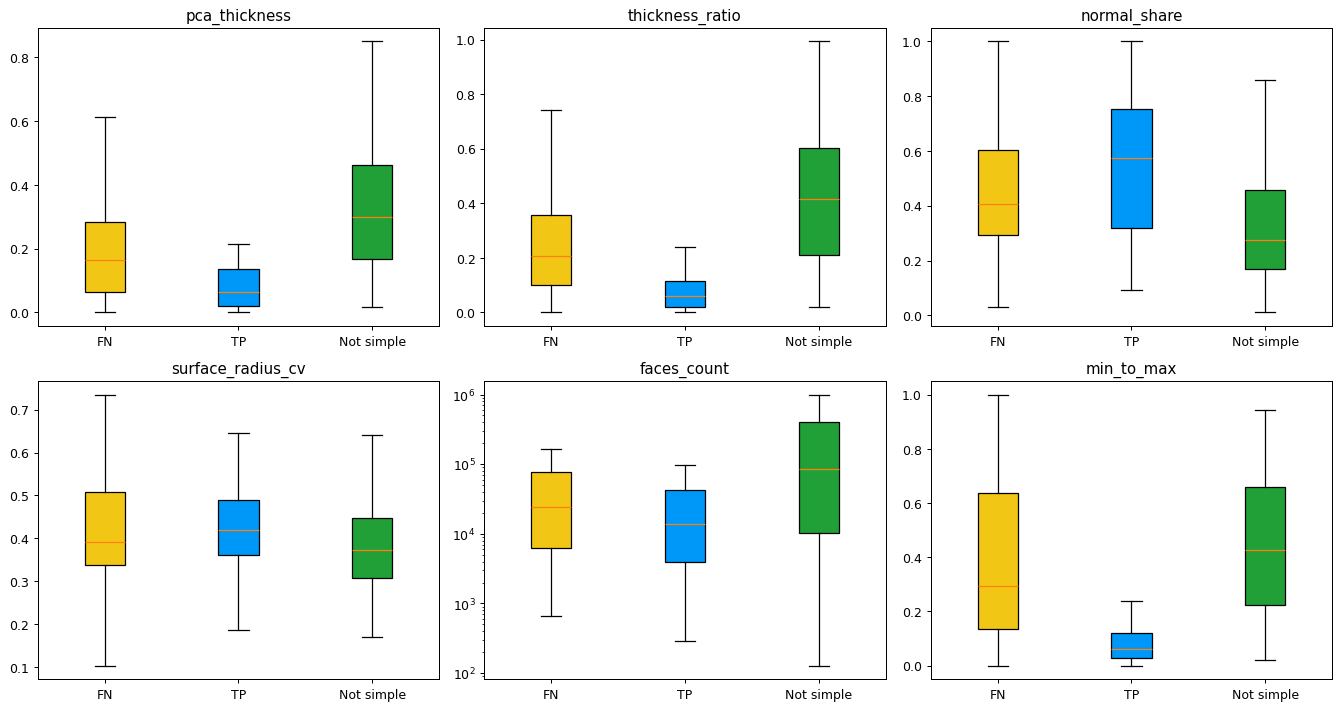

In [15]:
columns = ['pca_thickness', 'thickness_ratio', 'normal_share',
           'surface_radius_cv', 'faces_count', 'min_to_max']
group_order = ['FN', 'TP', 'Not simple']
colors = ['#F2C614', '#0098F8', '#21A038']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, columns):
    values = [geometry.loc[geometry['group'].eq(group), column].dropna()
              for group in group_order]
    boxes = ax.boxplot(values, labels=group_order, patch_artist=True, showfliers=False)
    for box, color in zip(boxes['boxes'], colors):
        box.set_facecolor(color)
    if column == 'faces_count':
        ax.set_yscale('log')
    ax.set_title(column)
plt.tight_layout()
plt.show()

## 15. Примеры по геометрическим признакам

Самые тонкие по PCA


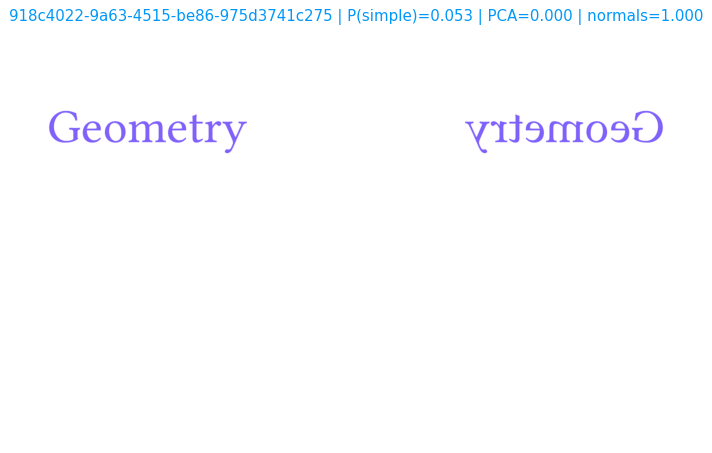

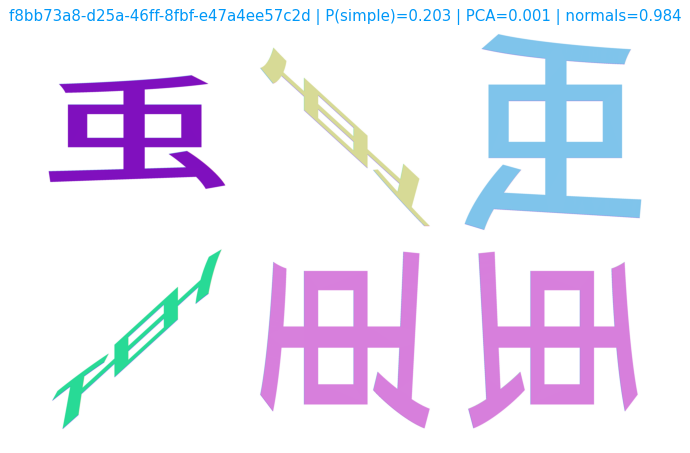

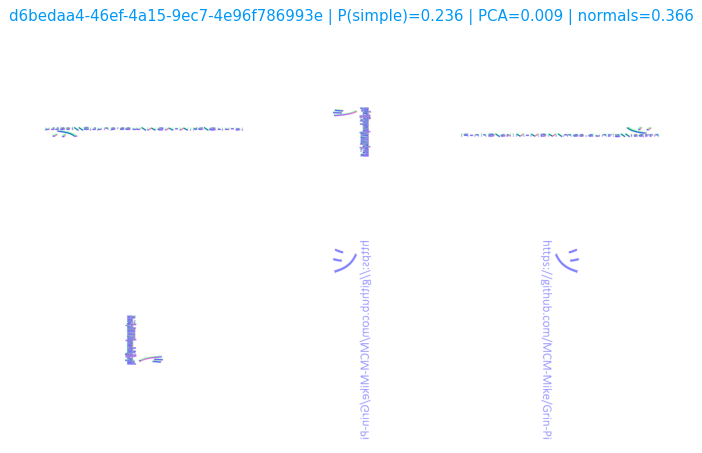

Большая доля параллельных нормалей


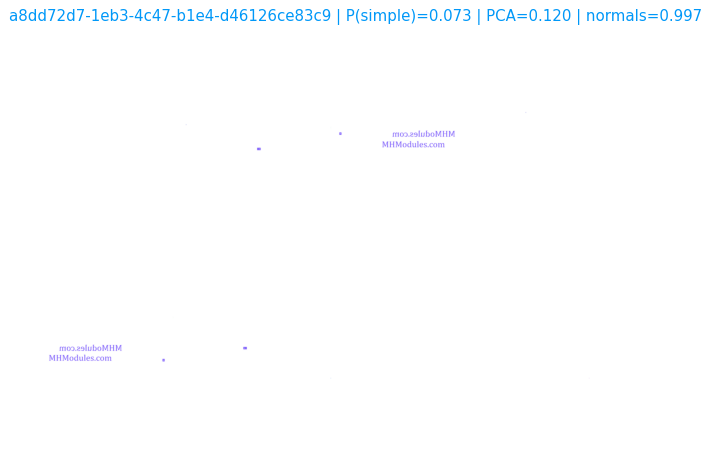

Меньше всего граней


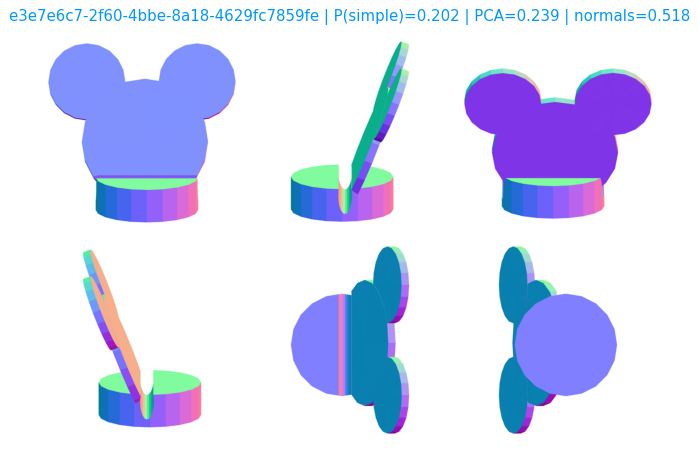

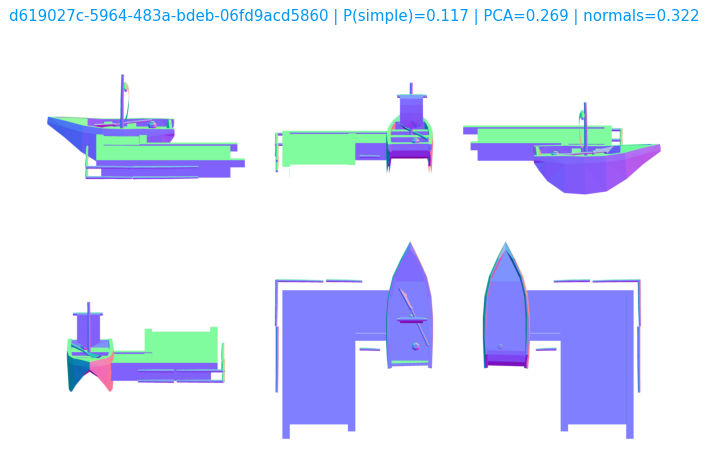

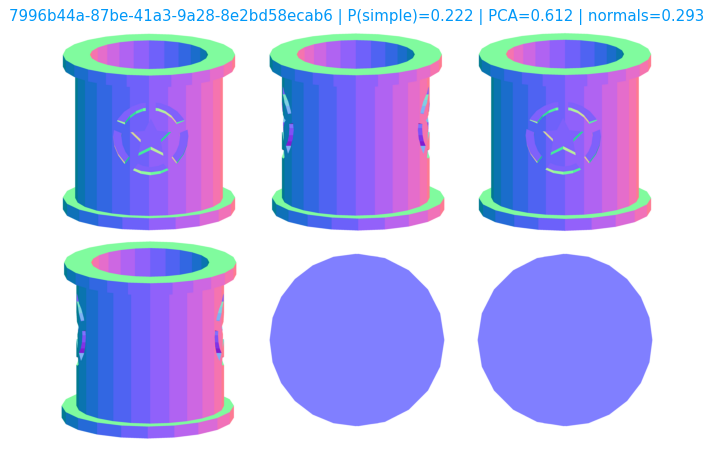

In [16]:
# Это кандидаты для просмотра, а не готовые метки подтипов.
missed_geometry = geometry[geometry['group'].eq('FN')]
selections = [
    ('Самые тонкие по PCA', missed_geometry.nsmallest(3, 'pca_thickness')),
    ('Большая доля параллельных нормалей', missed_geometry.nlargest(3, 'normal_share')),
    ('Меньше всего граней', missed_geometry.nsmallest(3, 'faces_count'))
]
shown = set()
for title, rows in selections:
    print(title)
    for _, row in rows.iterrows():
        if row['item_id'] in shown:
            continue
        shown.add(row['item_id'])
        with Image.open(train_dir / f"{row['item_id']}.png") as image:
            plt.figure(figsize=(12, 6))
            plt.imshow(image)
            plt.title(f"{row['item_id']} | P(simple)={row['probability']:.3f} | "
                      f"PCA={row['pca_thickness']:.3f} | normals={row['normal_share']:.3f}",
                      color='#0098F8')
            plt.axis('off')
            plt.show()

## 16. Разбор подтипов simple

В разметке нет подтипов: их нужно проверять по изображениям. Низкая толщина сама по себе не означает логотип. Число примитивов, плоских объектов и выдавленных изображений считаем только после просмотра.

Файл для разбора: D:\asg\СОРЕВНОВАНИЯ\AI challenge main\labels\simple\simple_geometry_review.csv
subtype
extruded     28
other        11
flat          8
unclear       8
primitive     5
Name: count, dtype: int64


,objects,median_thickness,median_faces
subtype,,,
extruded,28,0.097,27451.0
flat,8,0.083,22724.5
other,11,0.269,11748.0
primitive,5,0.294,70000.0
unclear,8,0.292,61392.0


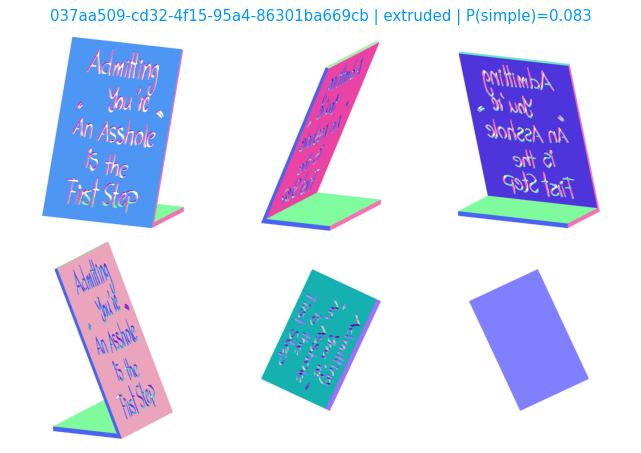

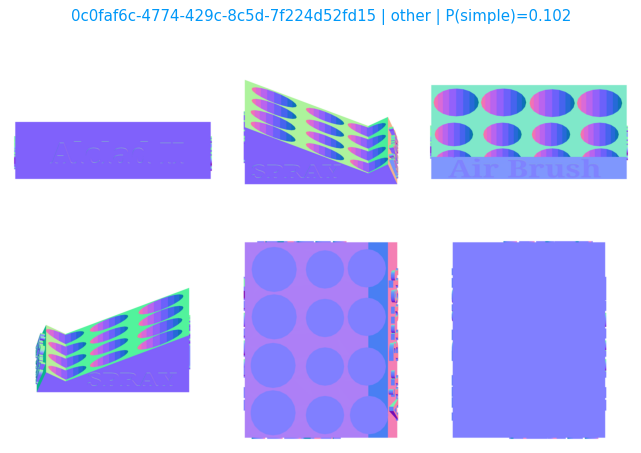

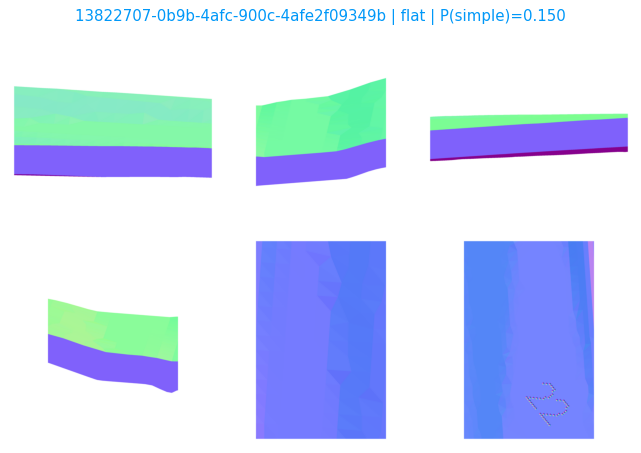

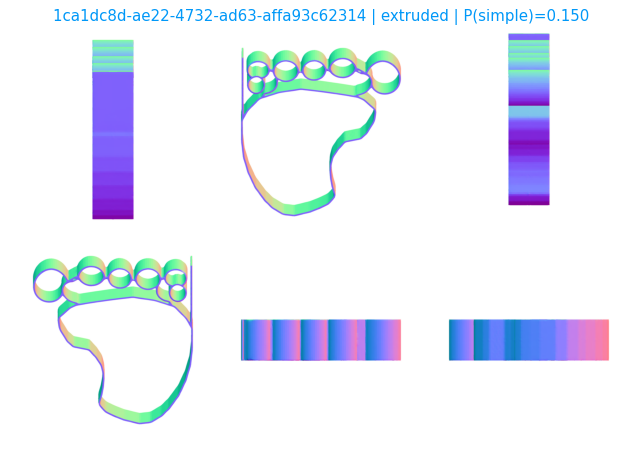

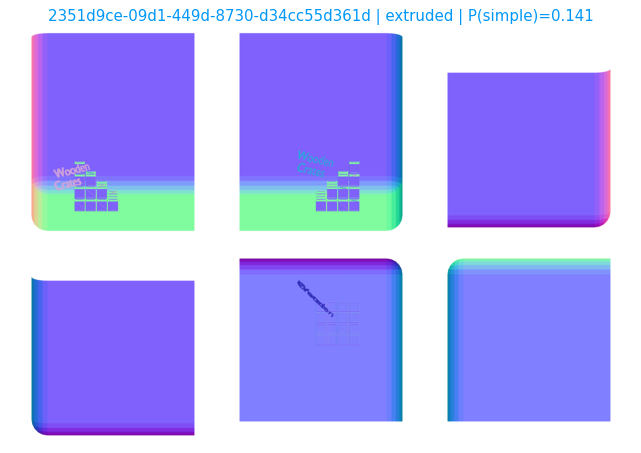

In [17]:
# Ручной просмотр: это предварительные подтипы, не исходная разметка.
review_path = ROOT / 'labels' / 'simple' / 'simple_geometry_review.csv'
if not review_path.exists():
    review = missed_geometry[['item_id']].copy()
    review['subtype'] = ''
    review['notes'] = ''
    review.to_csv(review_path, index=False)
annotations = pd.read_csv(review_path).fillna('')
assert set(annotations['item_id']) == set(fn_rows['item_id'])
review = missed_geometry.merge(annotations, on='item_id', validate='one_to_one')
print('Файл для разбора:', review_path)
print(review['subtype'].replace('', 'Не разобрано').value_counts())
display(review.groupby('subtype').agg(
    objects=('item_id', 'size'), median_thickness=('pca_thickness', 'median'),
    median_faces=('faces_count', 'median')
).round(3))

# Для отдельного подтипа: selected = review[review['subtype'].eq('extruded')]
selected = review
START = 0
for _, row in selected.iloc[START:START + 5].iterrows():
    with Image.open(train_dir / f"{row['item_id']}.png") as image:
        plt.figure(figsize=(12, 6))
        plt.imshow(image)
        plt.title(f"{row['item_id']} | {row['subtype']} | P(simple)={row['probability']:.3f}",
                  color='#0098F8')
        plt.axis('off')
        plt.show()

## 17. CatBoost: одинаковое разбиение

In [18]:
train_df = train_val_df.drop(index=val_index).reset_index(drop=True)
assert train_df['item_id'].is_unique and val_df['item_id'].is_unique
assert set(train_df['item_id']).isdisjoint(val_df['item_id'])
new_columns = ['pca_thickness', 'pca_line_ratio', 'thickness_ratio',
               'normal_share', 'surface_radius_cv']
base_columns = config['feature_columns']
extra_columns = base_columns + new_columns
print('Train:', len(train_df), 'Validation:', len(val_df))
print('Признаков:', len(base_columns), 'и', len(extra_columns))

Train: 6259 Validation: 1361
Признаков: 44 и 49


## 18. Новая геометрия для train и validation

In [19]:
from concurrent.futures import ThreadPoolExecutor

all_ids = pd.concat([train_df['item_id'], val_df['item_id']], ignore_index=True)
cached = pd.read_csv(cache_path)
assert cached['item_id'].is_unique
records = cached.to_dict('records')
done = set(cached['item_id'])
missing_ids = [item_id for item_id in all_ids if item_id not in done]
print('Осталось посчитать:', len(missing_ids))

# Два потока для загрузки NPZ, сохранение каждые 100 объектов.
try:
    with ThreadPoolExecutor(max_workers=2) as pool:
        rows = pool.map(geometry_features, missing_ids)
        for number, (item_id, row) in enumerate(zip(missing_ids, rows), start=1):
            records.append({'item_id': item_id, **row})
            if number % 100 == 0:
                pd.DataFrame(records).to_csv(cache_path, index=False)
                print('Посчитано:', number, '/', len(missing_ids), flush=True)
finally:
    pd.DataFrame(records).to_csv(cache_path, index=False)

new_features = pd.DataFrame(records).set_index('item_id')[new_columns]
all_features = features[base_columns].join(new_features, validate='one_to_one')
X_train_geometry = all_features.loc[train_df['item_id'], extra_columns]
X_val_geometry = all_features.loc[val_df['item_id'], extra_columns]
assert X_train_geometry.index.tolist() == train_df['item_id'].tolist()
assert X_val_geometry.index.tolist() == val_df['item_id'].tolist()
# Неопределённые признаки вырожденных мешей остаются NaN, CatBoost умеет с ними работать.
assert not np.isinf(X_train_geometry.to_numpy()).any()
assert not np.isinf(X_val_geometry.to_numpy()).any()
print('NaN train:', int(X_train_geometry.isna().sum().sum()),
      'NaN validation:', int(X_val_geometry.isna().sum().sum()))

Осталось посчитать: 7440
Посчитано: 100 / 7440
Посчитано: 200 / 7440
Посчитано: 300 / 7440
Посчитано: 400 / 7440
Посчитано: 500 / 7440
Посчитано: 600 / 7440
Посчитано: 700 / 7440
Посчитано: 800 / 7440
Посчитано: 900 / 7440
Посчитано: 1000 / 7440
Посчитано: 1100 / 7440
Посчитано: 1200 / 7440
Посчитано: 1300 / 7440
Посчитано: 1400 / 7440
Посчитано: 1500 / 7440
Посчитано: 1600 / 7440
Посчитано: 1700 / 7440
Посчитано: 1800 / 7440
Посчитано: 1900 / 7440
Посчитано: 2000 / 7440
Посчитано: 2100 / 7440
Посчитано: 2200 / 7440
Посчитано: 2300 / 7440
Посчитано: 2400 / 7440
Посчитано: 2500 / 7440
Посчитано: 2600 / 7440
Посчитано: 2700 / 7440
Посчитано: 2800 / 7440
Посчитано: 2900 / 7440
Посчитано: 3000 / 7440
Посчитано: 3100 / 7440
Посчитано: 3200 / 7440
Посчитано: 3300 / 7440
Посчитано: 3400 / 7440
Посчитано: 3500 / 7440
Посчитано: 3600 / 7440
Посчитано: 3700 / 7440
Посчитано: 3800 / 7440
Посчитано: 3900 / 7440
Посчитано: 4000 / 7440
Посчитано: 4100 / 7440
Посчитано: 4200 / 7440
Посчитано: 4300 / 

## 19. Сравнение 44 и 49 признаков

In [20]:
from sklearn.metrics import average_precision_score

parameters = config['parameters'].copy()
threshold_grid = np.arange(0.05, 0.96, 0.01)
y_val_simple = val_df['simple'].to_numpy()
experiment_models = {}
experiment_predictions = {}
experiment_probabilities = {}
experiment_thresholds = {}
experiment_rows = []

for name, columns in [('44 features', base_columns), ('49 features', extra_columns)]:
    candidate = CatBoostClassifier(**parameters)
    candidate.fit(
        X_train_geometry[columns], train_df['simple'],
        eval_set=(X_val_geometry[columns], y_val_simple),
        early_stopping_rounds=50, verbose=False
    )
    probabilities = candidate.predict_proba(X_val_geometry[columns])[:, 1]
    scores = [f1_score(y_val_simple, probabilities >= t) for t in threshold_grid]
    threshold = float(threshold_grid[np.argmax(scores)])
    predicted = probabilities >= threshold
    experiment_rows.append({
        'model': name, 'trees': candidate.tree_count_, 'threshold': threshold,
        'F1@0.5': f1_score(y_val_simple, probabilities >= 0.5),
        'F1': f1_score(y_val_simple, predicted),
        'AP': average_precision_score(y_val_simple, probabilities),
        'precision': precision_score(y_val_simple, predicted),
        'recall': recall_score(y_val_simple, predicted),
        'FP': int(((y_val_simple == 0) & predicted).sum()),
        'FN': int(((y_val_simple == 1) & ~predicted).sum())
    })
    experiment_models[name] = candidate
    experiment_predictions[name] = predicted
    experiment_probabilities[name] = probabilities
    experiment_thresholds[name] = threshold
    print(name, 'готово', flush=True)

experiment_results = pd.DataFrame(experiment_rows)
display(experiment_results.round(4))
baseline_predicted = experiment_predictions['44 features']
extra_predicted = experiment_predictions['49 features']
print('Совпадение с сохранённым CatBoost:',
      np.mean(baseline_predicted == val_df['prediction'].to_numpy()))
print('Изменение F1:', round(experiment_results.iloc[1]['F1']
                              - experiment_results.iloc[0]['F1'], 4))

44 features готово
49 features готово


,model,trees,threshold,F1@0.5,F1,AP,precision,recall,FP,FN
0,44 features,408,0.25,0.6257,0.6805,0.7308,0.5964,0.7924,155,60
1,49 features,355,0.24,0.6402,0.6958,0.7422,0.6005,0.8270,159,50


Совпадение с сохранённым CatBoost: 1.0
Изменение F1: 0.0152


## 20. Какие ошибки исправились

In [21]:
positive = y_val_simple == 1
negative = ~positive
changes = {
    'Исправленные пропуски': positive & ~baseline_predicted & extra_predicted,
    'Новые пропуски': positive & baseline_predicted & ~extra_predicted,
    'Исправленные ложные срабатывания': negative & baseline_predicted & ~extra_predicted,
    'Новые ложные срабатывания': negative & ~baseline_predicted & extra_predicted
}
display(pd.Series({name: int(mask.sum()) for name, mask in changes.items()}, name='Объектов'))

comparison = val_df[['item_id', 'simple']].copy()
comparison['baseline_prediction'] = baseline_predicted
comparison['geometry_prediction'] = extra_predicted
review_changes = review.merge(comparison[['item_id', 'baseline_prediction', 'geometry_prediction']],
                               on='item_id', validate='one_to_one')
review_changes = review_changes[~review_changes['baseline_prediction']]
display(review_changes.groupby('subtype').agg(
    missed_before=('item_id', 'size'), recovered=('geometry_prediction', 'sum')
))

importance = pd.Series(experiment_models['49 features'].feature_importances_,
                       index=extra_columns).sort_values(ascending=False)
display(importance.loc[new_columns].sort_values(ascending=False).rename('Importance'))

Исправленные пропуски               12
Новые пропуски                       2
Исправленные ложные срабатывания    18
Новые ложные срабатывания           22
Name: Объектов, dtype: int64

,missed_before,recovered
subtype,,
extruded,28,8
flat,8,2
other,11,1
primitive,5,0
unclear,8,1


thickness_ratio      8.752810
normal_share         5.059009
pca_thickness        3.828361
pca_line_ratio       1.607828
surface_radius_cv    1.582758
Name: Importance, dtype: float64

## 21. Сохранение эксперимента

In [22]:
MODEL_DIR = ROOT / 'labels' / 'simple' / 'models'
MODEL_DIR.mkdir(exist_ok=True)
metadata = {'parameters': parameters, 'target': 'simple', 'seed': 42,
            'threshold_grid': threshold_grid.tolist(), 'variants': {}}
for name, filename, columns in [
    ('44 features', 'simple_catboost_44.cbm', base_columns),
    ('49 features', 'simple_catboost_49.cbm', extra_columns)
]:
    experiment_models[name].save_model(str(MODEL_DIR / filename))
    metadata['variants'][name] = {
        'file': filename, 'feature_columns': columns,
        'threshold': experiment_thresholds[name],
        'validation_f1': float(experiment_results.set_index('model').loc[name, 'F1'])
    }
with open(MODEL_DIR / 'simple_catboost_geometry.json', 'w', encoding='utf-8') as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)
experiment_results.to_csv(MODEL_DIR / 'simple_catboost_geometry_results.csv', index=False)
for name, column in [('44 features', 'baseline_probability'),
                     ('49 features', 'geometry_probability')]:
    comparison[column] = experiment_probabilities[name]
comparison.to_csv(MODEL_DIR / 'simple_catboost_geometry_validation.csv', index=False)
print('Результаты сохранены в', MODEL_DIR)

Результаты сохранены в D:\asg\СОРЕВНОВАНИЯ\AI challenge main\labels\simple\models
